# MAESTRO data and label audit
49 authentic recordings contain natural overlapping environmental sounds. This notebook measures recording allocation, annotation coverage and rare-class support from the pinned private cache. It prints aggregate counts only. No test predictions are computed; label plots use train and validation.

MAESTRO has custom experimental/noncommercial terms. Keep its notice with private data. The 29/10/10 recording split is a portfolio holdout, not the official DCASE five-fold benchmark.

In [1]:
from pathlib import Path
import sys, json, math, hashlib, time
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
CACHE=ROOT/'data/features/five-second-cache'
FIGURES=ROOT/'assets/figures'
FIGURES.mkdir(parents=True,exist_ok=True)
def show(fig,name):
    fig.tight_layout(pad=1.5,w_pad=4)
    fig.savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    display(fig); plt.close(fig)
def report(name): return json.loads((ROOT/'docs'/name).read_text(encoding='utf-8'))

In [2]:
metadata=json.loads((CACHE/'metadata.json').read_text(encoding='utf-8'))
classes=metadata['classes']
source_frame=pd.DataFrame([{'split':metadata['assignment'][r['id']],'scene':r['id'].rsplit('_',1)[0],'seconds':r['seconds']} for r in metadata['sources']])
summary=source_frame.groupby('split').agg(recordings=('seconds','size'),seconds=('seconds','sum'))
display(summary)
display(pd.DataFrame({'contract':['sample_rate','context_seconds','encoder_weight_sha256'],'value':[metadata[k] for k in ('sample_rate','context_seconds','encoder_weight_sha256')]}))
assert summary['recordings'].to_dict()=={'test':10,'train':29,'validation':10}

,recordings,seconds
split,,
test,10,2368
train,29,6838
validation,10,2163


,contract,value
0,sample_rate,32000
1,context_seconds,5
2,encoder_weight_sha256,0dc499e40e9761ef5ea061ffc77697697f277f6a960894...


## Recording durations and scene allocation
Different seconds from one recording remain together.

split,test,train,validation
scene,,,
cafe_restaurant,2,6,2
city_center,2,6,2
grocery_store,2,5,2
metro_station,2,5,2
residential_area,2,7,2


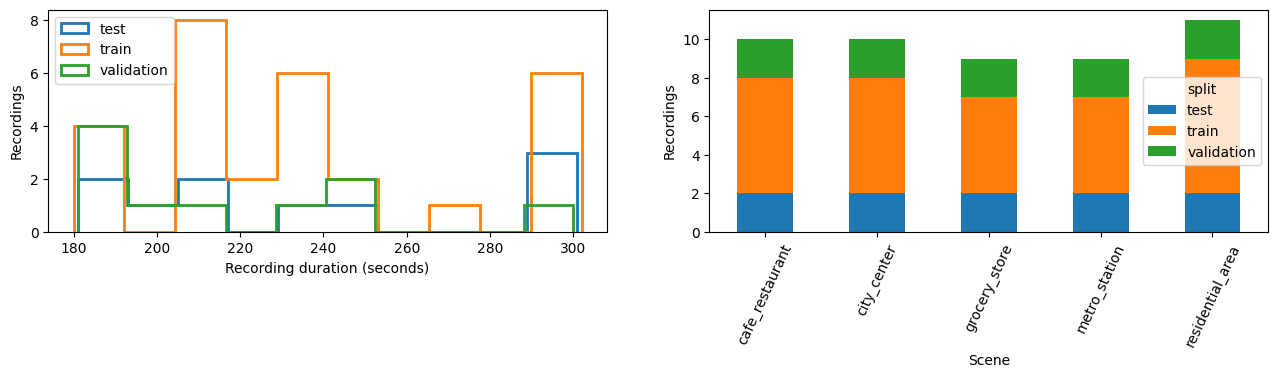

In [3]:
scene_counts=pd.crosstab(source_frame['scene'],source_frame['split'])
display(scene_counts)
fig,axes=plt.subplots(1,2,figsize=(13,4))
for split,block in source_frame.groupby('split'):
    axes[0].hist(block['seconds'],bins=10,histtype='step',linewidth=2,label=split)
axes[0].set(xlabel='Recording duration (seconds)',ylabel='Recordings'); axes[0].legend()
scene_counts.plot.bar(stacked=True,ax=axes[1]); axes[1].set(ylabel='Recordings',xlabel='Scene'); axes[1].tick_params(axis='x',rotation=65)
show(fig,'audio_recording_audit.png')

## Known annotations and positive support
Unknown scene classes are masked. Training uses soft human scores; evaluation uses strict target > 0.5.

In [4]:
arrays={}; class_rows=[]
for split in ('train','validation'):
    assert hashlib.sha256((CACHE/(split+'.npz')).read_bytes()).hexdigest()==metadata['contracts'][split]['sha256']
    with np.load(CACHE/(split+'.npz'),allow_pickle=False) as archive:
        y,mask,ids=archive['targets'],archive['masks'],archive['record_ids']
    assert np.isfinite(y).all() and np.isin(mask,[0,1]).all()
    assert (y>=0).all() and (y<=1).all()
    arrays[split]=(y,mask,ids)
    for j,label in enumerate(classes):
        observed=mask[:,j]==1
        class_rows.append({'split':split,'class':label,'known_seconds':int(observed.sum()),'hard_positive_seconds':int(((y[:,j]>.5)&observed).sum()),'mean_soft_target_known':float(y[observed,j].mean()) if observed.any() else np.nan,'known_fraction':float(observed.mean())})
assert set(arrays['train'][2]).isdisjoint(set(arrays['validation'][2]))
support=pd.DataFrame(class_rows)
display(support.pivot(index='class',columns='split',values='hard_positive_seconds'))

split,train,validation
class,,
announcement,0,0
birds_singing,1204,212
brakes_squeaking,45,10
car,2134,690
cash register beeping,0,0
children voices,63,7
coffee machine,16,0
cutlery and dishes,120,25
door opens/closes,0,1


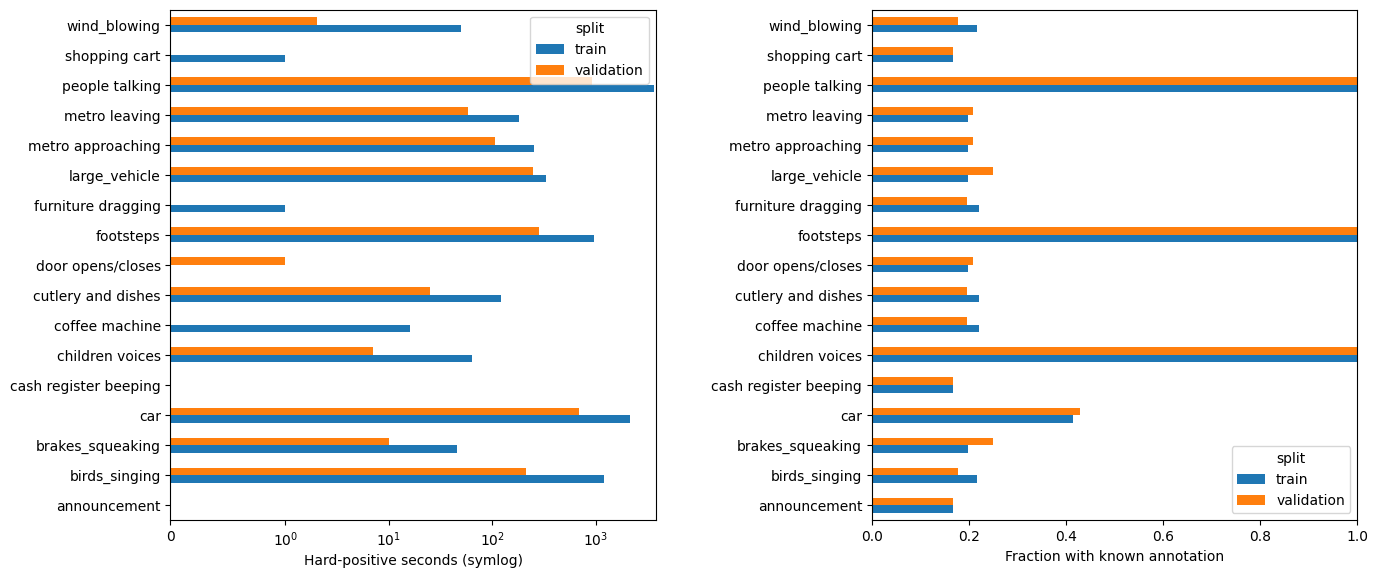

In [5]:
fig,axes=plt.subplots(1,2,figsize=(14,6))
support.pivot(index='class',columns='split',values='hard_positive_seconds').plot.barh(ax=axes[0])
axes[0].set_xscale('symlog',linthresh=1); axes[0].set(xlabel='Hard-positive seconds (symlog)',ylabel='')
support.pivot(index='class',columns='split',values='known_fraction').plot.barh(ax=axes[1])
axes[1].set(xlabel='Fraction with known annotation',ylabel='',xlim=(0,1))
show(fig,'audio_support_and_coverage.png')

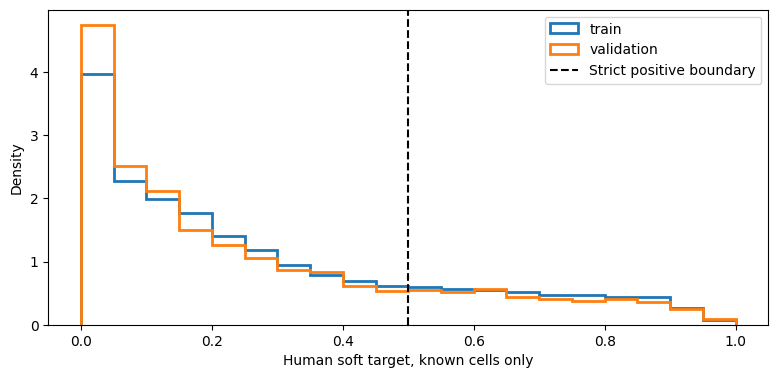

,class,hard_positive_seconds,known_seconds
0,announcement,0,1145
4,cash register beeping,0,1145
6,coffee machine,16,1504
8,door opens/closes,0,1353
10,furniture dragging,1,1504
15,shopping cart,1,1145


In [6]:
fig,ax=plt.subplots(figsize=(8,4))
for split,(y,mask,_) in arrays.items():
    ax.hist(y[mask==1],bins=np.linspace(0,1,21),density=True,histtype='step',linewidth=2,label=split)
ax.axvline(.5,linestyle='--',color='black',label='Strict positive boundary')
ax.set(xlabel='Human soft target, known cells only',ylabel='Density'); ax.legend()
show(fig,'audio_soft_target_distribution.png')
display(support[(support['split']=='train')&(support['hard_positive_seconds']<=16)][['class','hard_positive_seconds','known_seconds']])

Three classes have no training positives. Furniture dragging and shopping cart each have one; coffee machine has 16. Weighting cannot invent missing examples. Recording separation does not establish location/session independence.

In [7]:
audit=report('transfer-results.json')['source_alignment_audit']
display(pd.DataFrame([{'check':k,'value':v} for k,v in audit.items() if isinstance(v,(bool,str))]))

,check,value
0,all49_annotations_match_baseline,True
1,all49_audio_and_annotation_hashes_identical_be...,True
2,class_order_and_recording_assignment_match_bas...,True
3,test_class_positive_and_observed_counts_match_...,True
4,encoder_weight_sha256,0dc499e40e9761ef5ea061ffc77697697f277f6a960894...
5,all_candidate_losses_and_validation_scores_finite,True
6,all_best_epochs_match_validation_history,True
7,macro_scores_independently_recomputed_from_per...,True
